# 02. Model selection, training and evaluation

Reproduces the numbers in the README from the outputs of `ml/scripts/train_fusion.py` and `ml/scripts/eval_videos.py`.

**Method.** Five public pretrained deepfake classifiers are benchmarked zero-shot. A group-wise validation split carved out of the training data picks the best combination of backbones and the regularisation strength. A logistic-regression fusion head is trained on their frozen embeddings and logits, and evaluated once on the held-out test split.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "app").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
DATA = ROOT / "data" / "crops"
REPORTS = ROOT / "reports"
m = json.loads((REPORTS / 'metrics.json').read_text())
print('Chosen backbones:', m['chosen_backbones'])
print('C =', m['C'], '| split sizes:', m['split_sizes'])

Chosen backbones: ['buildborderless/CommunityForensics-DeepfakeDet-ViT', 'prithivMLmods/deepfake-detector-model-v1']
C = 0.02 | split sizes: {'train': 2826, 'val': 614, 'test': 1320}


## 1. Zero-shot benchmark of the candidates

Mean AUC across the four sources on the **validation** split, which is what model selection used.

In [2]:
pd.Series(m['zero_shot_val_auc']).sort_values(ascending=False).rename('validation AUC (mean over sources)')

CommunityForensics-DeepfakeDet-ViT    0.8350
deepfake-detector-model-v1            0.6813
ViT_Deepfake_Detection                0.5911
deepfake_vs_real_image_detection      0.5691
Deep-Fake-Detector-v2-Model           0.5021
Name: validation AUC (mean over sources), dtype: float64

## 2. Test results

Every row is evaluated on the same held-out test crops.

In [3]:
rows = []
for name, rep in m['test'].items():
    rows.append({'model': name, **{src: rep[src]['auc'] for src in ['ffhq_stylegan', 'dff', 'celebdf', 'dfd']},
                 'overall AUC': rep['overall']['auc'], 'accuracy': rep['overall']['accuracy'], 'F1': rep['overall']['f1']})
pd.DataFrame(rows).set_index('model').sort_values('overall AUC', ascending=False).round(3)

,ffhq_stylegan,dff,celebdf,dfd,overall AUC,accuracy,F1
model,,,,,,,
fusion_head,0.999,0.968,0.586,0.848,0.920,0.827,0.816
ensemble_mean,0.992,0.781,0.654,0.574,0.852,0.747,0.678
zero_shot:CommunityForensics-DeepfakeDet-ViT,1.000,0.929,0.488,0.700,0.816,0.725,0.644
zero_shot:deepfake-detector-model-v1,0.953,0.525,0.684,0.498,0.702,0.633,0.624
zero_shot:ViT_Deepfake_Detection,0.567,0.594,0.528,0.564,0.568,0.567,0.597
zero_shot:deepfake_vs_real_image_detection,0.554,0.577,0.534,0.552,0.557,0.562,0.579
zero_shot:Deep-Fake-Detector-v2-Model,0.530,0.488,0.547,0.495,0.514,0.496,0.553


## 3. Figures

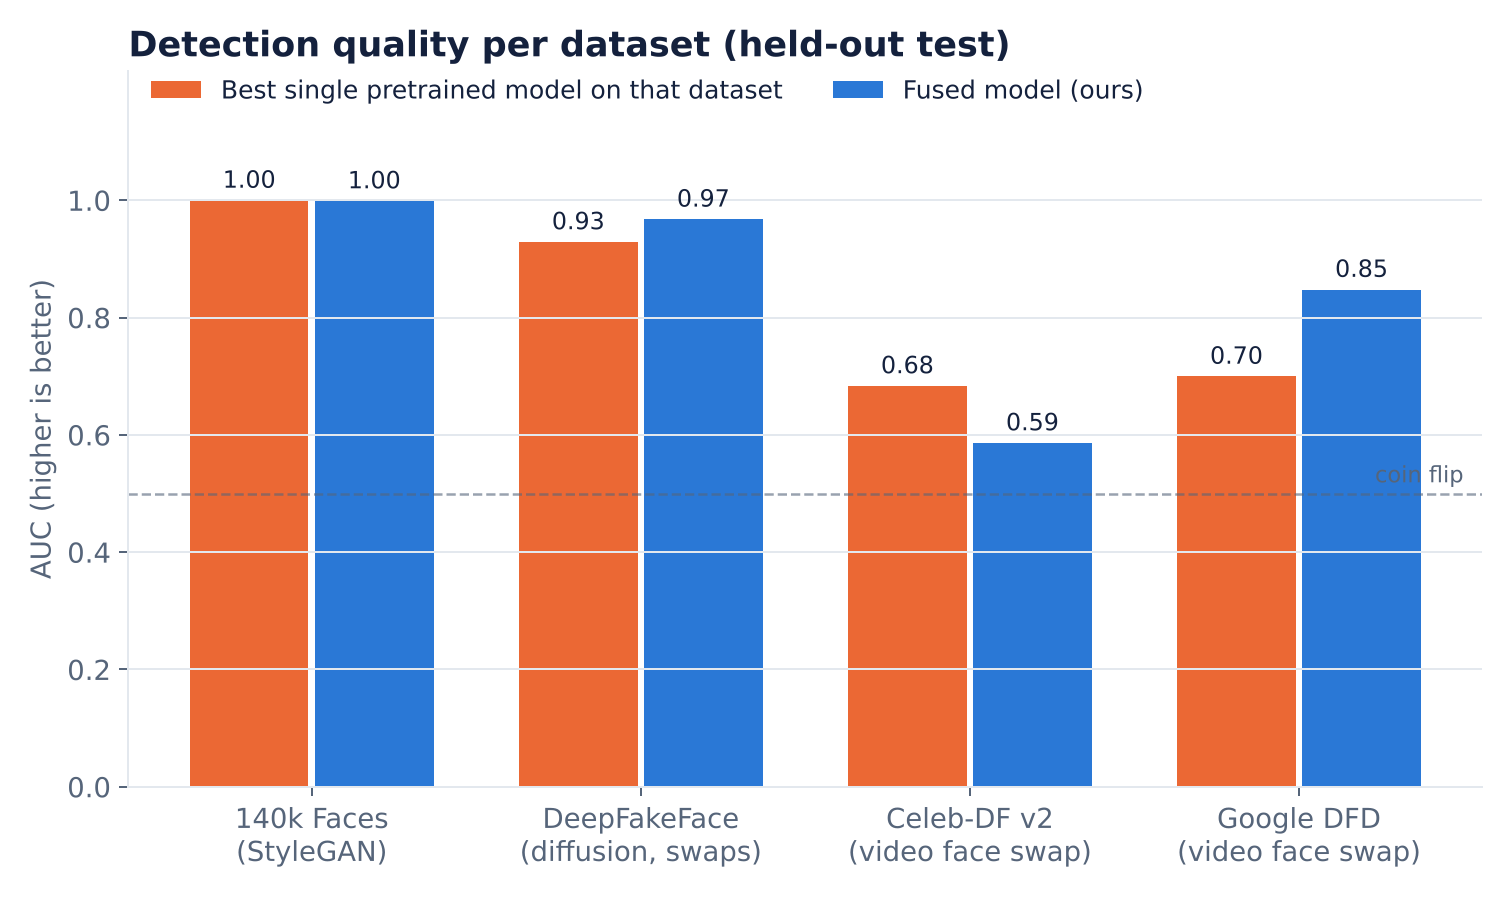

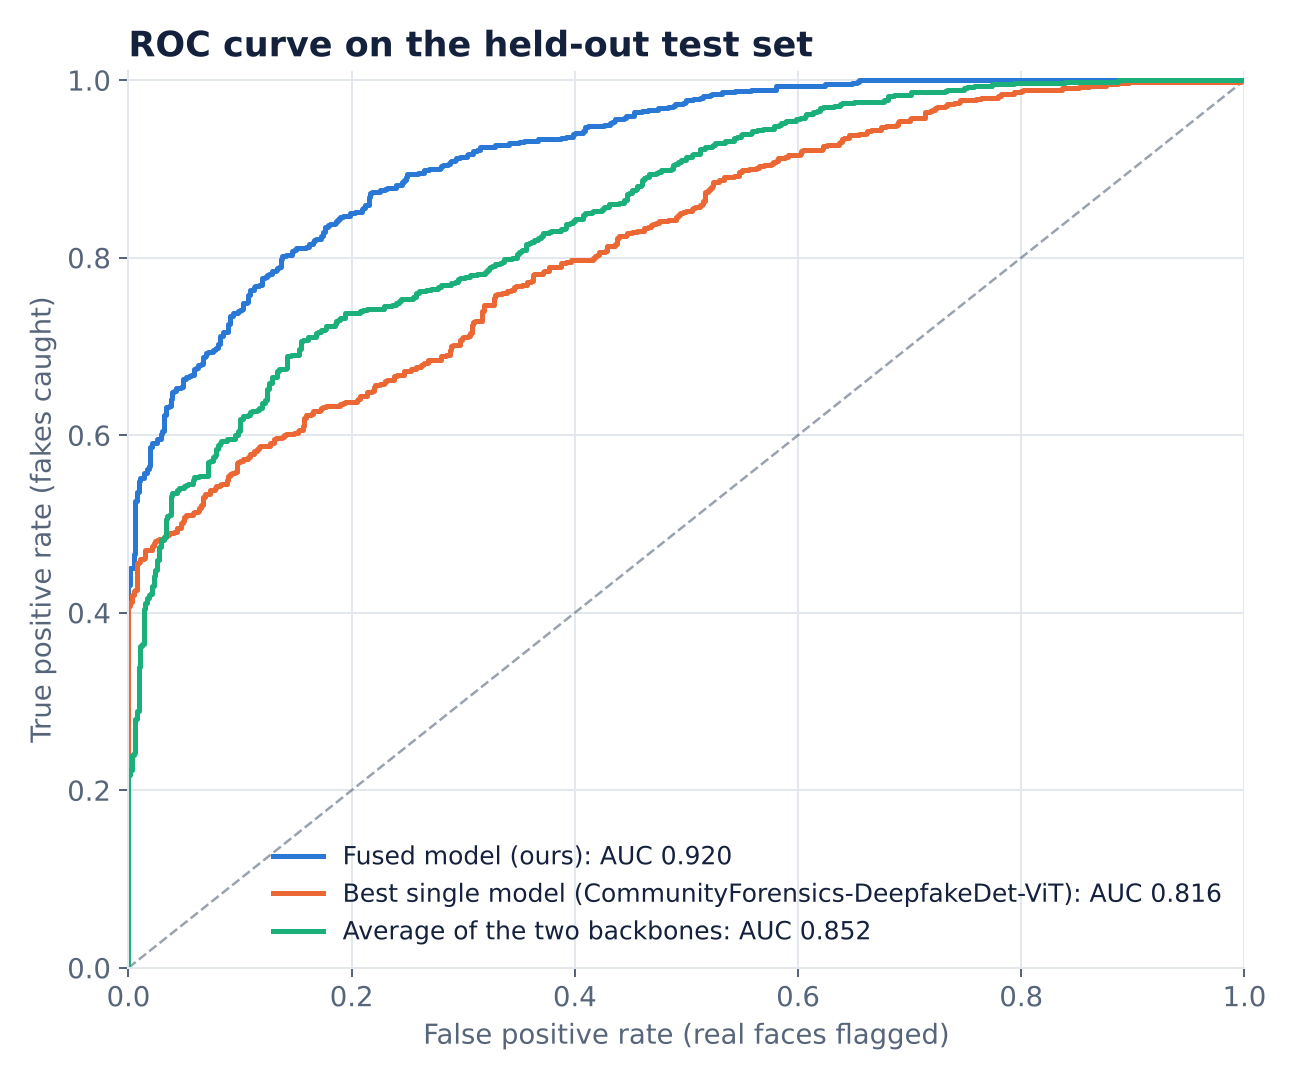

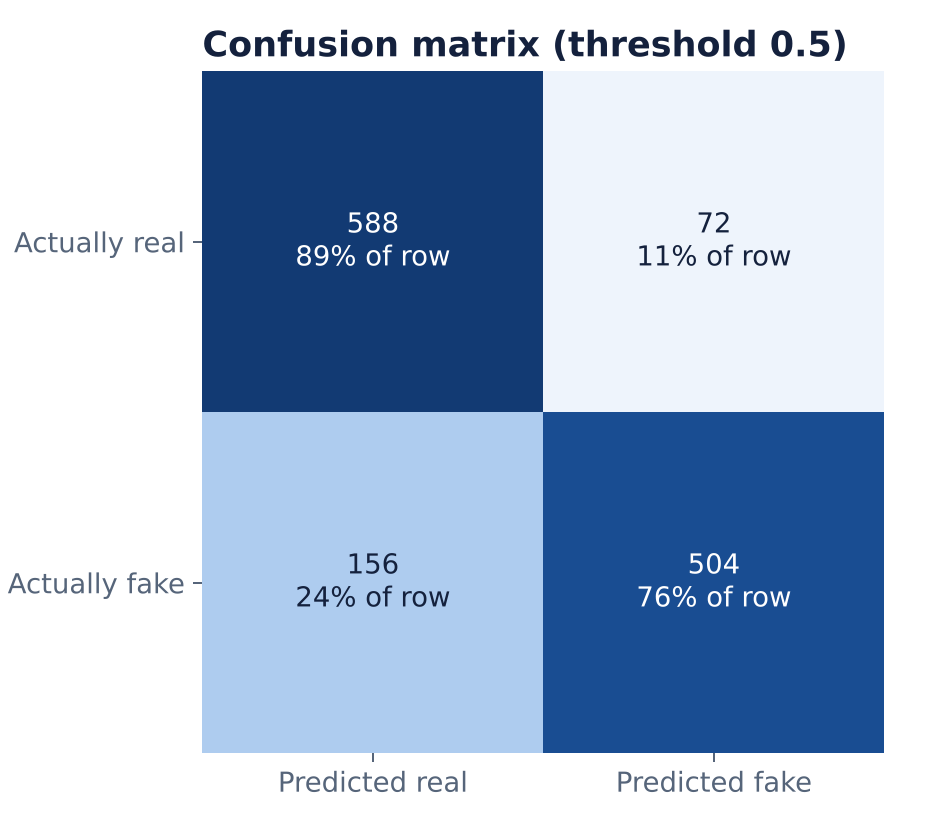

In [4]:
from IPython.display import Image as Show, display
for f in ['per_dataset_auc.png', 'roc.png', 'confusion_matrix.png']:
    display(Show(filename=str(REPORTS / f), width=640))

## 4. End-to-end video evaluation

Whole held-out videos run through the production pipeline (frame sampling, face detection, fusion, aggregation).

In [5]:
v = json.loads((REPORTS / 'video_metrics.json').read_text())
pd.DataFrame({k: v[k] for k in ['overall', 'celebdf', 'dfd']}).T[['auc', 'accuracy', 'precision', 'recall', 'f1', 'n']]

,auc,accuracy,precision,recall,f1,n
overall,0.7610,0.6889,0.6809,0.7111,0.6957,90.0
celebdf,0.7133,0.6500,0.6800,0.5667,0.6182,60.0
dfd,0.9511,0.7667,0.6818,1.0000,0.8108,30.0


In [6]:
print('Mean seconds per video:', v['mean_seconds_per_video'], '| share marked inconclusive:', v['uncertain_rate'])

Mean seconds per video: 18.09 | share marked inconclusive: 0.2


## 5. Error analysis

The most confident mistakes on the test set. These are the cases to discuss honestly in the presentation.

In [7]:
p = np.load(REPORTS / 'test_predictions.npz', allow_pickle=True)
df = pd.read_csv(DATA / 'manifest.csv'); test = df[df.split == 'test'].reset_index(drop=True)
test['p'] = p['p_fusion']; test['err'] = (test.p - test.label).abs()
worst = test.sort_values('err', ascending=False).head(8)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.8))
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(DATA / r.path)); ax.axis('off')
    ax.set_title(f"{r.source}\ntrue {'fake' if r.label else 'real'}, p={r.p:.2f}", fontsize=8)
plt.tight_layout()

Face images from the datasets are not stored in this notebook (dataset licenses). Run it locally after prepare_data.py to see them.


In [8]:
test.assign(wrong=(test.p >= 0.5) != test.label).groupby(['source', 'label']).wrong.mean().round(3).unstack().rename(columns={0: 'real flagged fake', 1: 'fake missed'})

label,real flagged fake,fake missed
source,,
celebdf,0.194,0.719
dfd,0.230,0.220
dff,0.067,0.127
ffhq_stylegan,0.032,0.000
